# Практическое задание «Коллаборативная фильтрация»

**Автор:** Александра Бужор (Alexandra Bujor) · Telegram: [@Angry_C_F_O](https://t.me/Angry_C_F_O)
**Датасет:** MovieLens 100K (`ml-100k`, встроенный датасет библиотеки `surprise`)
**Стек:** Python · pandas · NumPy · SciPy · Matplotlib · Seaborn · scikit-surprise

### Цель
Построить рекомендательную систему на основе коллаборативной фильтрации и сравнить два классических memory-based подхода — **User-based** (сходство пользователей) и **Item-based** (сходство фильмов): от анализа данных до проверки рекомендаций для конкретного пользователя.

### План работы
| Этап | Содержание |
|---|---|
| 1 | Загрузка `ml-100k` и приведение к структуре `surprise.Dataset` |
| 2 | EDA: распределение оценок, активность пользователей, популярность фильмов, **анализ разреженности** |
| 3 | User-based и Item-based KNN (`KNNBasic`, косинусная мера), диагностика матриц сходства |
| 4 | Кросс-валидация на 5 фолдах, RMSE и MAE, ручной расчёт метрик, сравнение с бейзлайнами по KPI |
| 5 | Рекомендации для случайного пользователя, проверка на выборке пользователей, итоговая таблица и выводы |

### KPI — критерии эффективности модели
KPI зафиксированы **до** обучения моделей, чтобы оценка не подстраивалась под результат. Ориентиры — два бейзлайна, которые не используют сходство между пользователями или фильмами:

* **Глобальное среднее** — каждой паре «пользователь — фильм» предсказывается средняя оценка обучающей выборки. Модель, которая не лучше этого уровня, бесполезна.
* **`BaselineOnly`** — модель смещений $\hat r_{ui} = \mu + b_u + b_i$: учитывает только «строгость» пользователя и общее восприятие фильма. Коллаборативная фильтрация оправдана, только если информация о соседях даёт точность выше, чем одни смещения.

| Класс | Условие |
|---|---|
| **Эффективна** | RMSE и MAE ниже, чем у `BaselineOnly`, на каждом из 5 фолдов |
| **Пограничная** | в среднем лучше `BaselineOnly` хотя бы по одной метрике, но не на всех фолдах |
| **Неэффективна** | лучше глобального среднего, но не лучше `BaselineOnly` |
| **Бесполезна** | RMSE не ниже, чем у глобального среднего |

**Метрики** (чем ниже, тем лучше):
* $\text{RMSE} = \sqrt{\frac{1}{|T|}\sum_{(u,i) \in T} (r_{ui}-\hat r_{ui})^2}$ — корень из среднего квадрата ошибки, сильнее штрафует крупные промахи;
* $\text{MAE} = \frac{1}{|T|}\sum_{(u,i) \in T} |r_{ui}-\hat r_{ui}|$ — средняя абсолютная ошибка в «звёздах».

## 0. Подготовка окружения
Если библиотеки `surprise` нет (например, в Google Colab), она устанавливается автоматически.

In [9]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('surprise') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-surprise'])

In [10]:
import os
import random

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from IPython.display import display

import surprise
from surprise import (AlgoBase, BaselineOnly, Dataset, KNNBaseline, KNNBasic, KNNWithMeans,
                      NormalPredictor, Reader, SVD, accuracy, get_dataset_dir)
from surprise.model_selection import KFold, cross_validate

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Цвет закреплён за смыслом во всех графиках:
# синий — пользователи / User-based, оранжевый — фильмы / Item-based,
# зелёный — SVD, серый — бейзлайны, фиолетовый — сами оценки
C_USER, C_ITEM, C_SVD, C_BASE, C_RATING = '#2a78d6', '#eb6834', '#1baf7a', '#898781', '#6250d6'
INK, INK_2, GRID, AXIS = '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'legend.frameon': False, 'legend.fontsize': 9,
})
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.width', 200)


def fmt_int(x):
    """Целое число с пробелом в качестве разделителя разрядов."""
    return f'{int(x):,}'.replace(',', ' ')


print(f'Python {sys.version.split()[0]} | surprise {surprise.__version__} | '
      f'pandas {pd.__version__} | numpy {np.__version__}')

Python 3.13.6 | surprise 1.1.5 | pandas 3.1.1 | numpy 2.5.4


## Этап 1. Загрузка и подготовка данных
MovieLens 100K — 100 000 оценок по шкале 1–5 от 943 пользователей для 1 682 фильмов (сентябрь 1997 — апрель 1998); у каждого пользователя не менее 20 оценок.

`Dataset.load_builtin('ml-100k')` при первом запуске скачивает архив в `~/.surprise_data` и возвращает объект `Dataset` с готовым `Reader`: формат строки `user item rating timestamp`, разделитель — табуляция, шкала 1–5. Параметр `prompt=False` отключает вопрос «скачать? [Y/n]».

In [11]:
data = Dataset.load_builtin('ml-100k', prompt=False)

print('Тип объекта:', type(data).__name__)
print('Число оценок:', fmt_int(len(data.raw_ratings)))
print('Шкала оценок (Reader):', data.reader.rating_scale)
print('Первые записи (user, item, rating, timestamp):')
data.raw_ratings[:5]

Тип объекта: DatasetAutoFolds
Число оценок: 100 000
Шкала оценок (Reader): (1, 5)
Первые записи (user, item, rating, timestamp):


[('196', '242', 3.0, '881250949'),
 ('186', '302', 3.0, '891717742'),
 ('22', '377', 1.0, '878887116'),
 ('244', '51', 2.0, '880606923'),
 ('166', '346', 1.0, '886397596')]

Для EDA переносим оценки в `pandas.DataFrame`, а названия и жанры фильмов берём из файла `u.item` того же архива. В `surprise` идентификаторы хранятся строками; в таблице `ratings` они приведены к целым числам.

In [12]:
ratings = pd.DataFrame(data.raw_ratings, columns=['user_id', 'item_id', 'rating', 'timestamp'])
ratings = ratings.astype({'user_id': int, 'item_id': int, 'rating': float, 'timestamp': int})

ML_DIR = os.path.join(get_dataset_dir(), 'ml-100k', 'ml-100k')
GENRES = ['unknown', 'Action', 'Adventure', 'Animation', "Children's", 'Comedy', 'Crime',
          'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery',
          'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
movies = pd.read_csv(os.path.join(ML_DIR, 'u.item'), sep='|', encoding='latin-1', header=None,
                     names=['item_id', 'title', 'release_date', 'video_release_date', 'imdb_url'] + GENRES)
genre_flags = movies[GENRES].to_numpy().astype(bool)
movies['genres'] = [', '.join(np.array(GENRES)[row]) for row in genre_flags]
movies = movies[['item_id', 'title', 'genres'] + GENRES]

display(ratings.head())
display(movies[['item_id', 'title', 'genres']].head())

,user_id,item_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


,item_id,title,genres
0,1,Toy Story (1995),"Animation, Children's, Comedy"
1,2,GoldenEye (1995),"Action, Adventure, Thriller"
2,3,Four Rooms (1995),Thriller
3,4,Get Shorty (1995),"Action, Comedy, Drama"
4,5,Copycat (1995),"Crime, Drama, Thriller"


**Проверка качества данных**

In [13]:
period = pd.to_datetime(ratings['timestamp'], unit='s')
quality = pd.Series({
    'Пропуски в оценках': int(ratings.isna().sum().sum()),
    'Повторные оценки одной пары (пользователь, фильм)': int(ratings.duplicated(['user_id', 'item_id']).sum()),
    'Допустимые значения оценок': ', '.join(str(int(v)) for v in sorted(ratings['rating'].unique())),
    'Оценки фильмов без описания в u.item': int((~ratings['item_id'].isin(movies['item_id'])).sum()),
    'ID пользователей': f"{ratings['user_id'].min()} … {ratings['user_id'].max()}",
    'ID фильмов': f"{ratings['item_id'].min()} … {ratings['item_id'].max()}",
    'Период оценок': f'{period.min():%d.%m.%Y} — {period.max():%d.%m.%Y}',
}, name='Результат').astype(str)
quality.to_frame()

,Результат
Пропуски в оценках,0
"Повторные оценки одной пары (пользователь, фильм)",0
Допустимые значения оценок,"1, 2, 3, 4, 5"
Оценки фильмов без описания в u.item,0
ID пользователей,1 … 943
ID фильмов,1 … 1682
Период оценок,20.09.1997 — 22.04.1998


Данные чистые: пропусков и повторных оценок нет, оценки — целые числа от 1 до 5, у каждого фильма есть описание, идентификаторы идут подряд без пропусков. Дополнительная очистка не требуется.

Для собственных данных структура `Dataset` собирается так же — через `Reader` и `Dataset.load_from_df`. Проверка на тех же оценках:

In [14]:
reader = Reader(rating_scale=(1, 5))
data_from_df = Dataset.load_from_df(ratings[['user_id', 'item_id', 'rating']], reader)
print('Оценок в Dataset, собранном из DataFrame:', fmt_int(len(data_from_df.raw_ratings)))
print('Совпадает со встроенным набором:', len(data_from_df.raw_ratings) == len(data.raw_ratings))

Оценок в Dataset, собранном из DataFrame: 100 000
Совпадает со встроенным набором: True


## Этап 2. Исследовательский анализ данных (EDA)
### 2.1. Размер и разреженность матрицы «пользователь × фильм»

In [15]:
n_users = ratings['user_id'].nunique()
n_items = ratings['item_id'].nunique()
n_ratings = len(ratings)
n_cells = n_users * n_items
density = n_ratings / n_cells

pd.DataFrame({'Значение': [fmt_int(n_users), fmt_int(n_items), fmt_int(n_ratings), fmt_int(n_cells),
                           f'{density:.2%}', f'{1 - density:.2%}',
                           f'{n_ratings / n_users:.1f}', f'{n_ratings / n_items:.1f}']},
             index=['Пользователей', 'Фильмов', 'Оценок', 'Ячеек в матрице user × item',
                    'Заполненность (density)', 'Разреженность (sparsity)',
                    'Оценок на пользователя (в среднем)', 'Оценок на фильм (в среднем)'])

,Значение
Пользователей,943
Фильмов,1 682
Оценок,100 000
Ячеек в матрице user × item,1 586 126
Заполненность (density),6.30%
Разреженность (sparsity),93.70%
Оценок на пользователя (в среднем),106.0
Оценок на фильм (в среднем),59.5


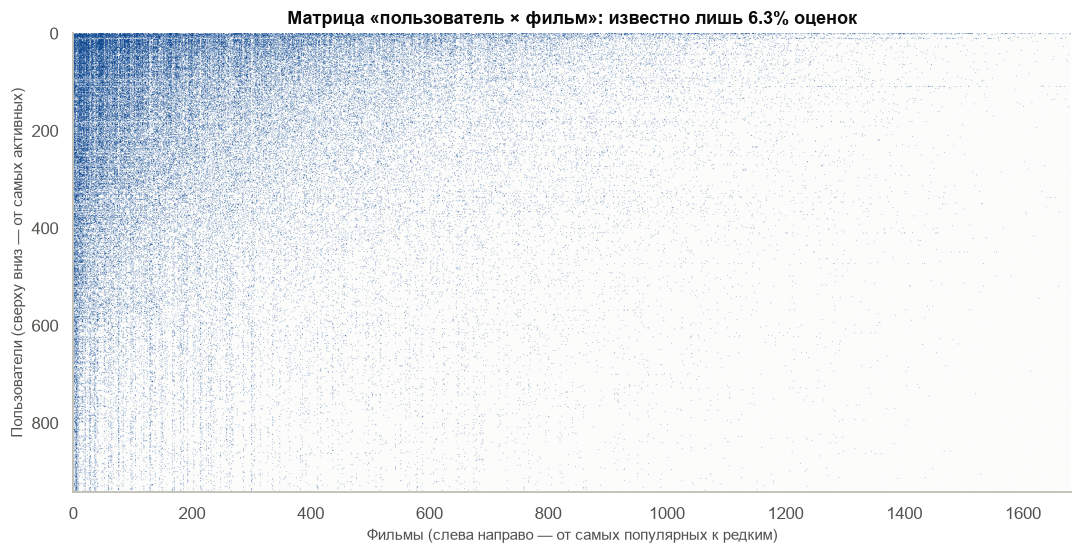

In [16]:
# Матрица, в которой пользователи упорядочены по активности, а фильмы — по популярности
user_order = ratings['user_id'].value_counts().index
item_order = ratings['item_id'].value_counts().index
row = pd.Series(np.arange(n_users), index=user_order).loc[ratings['user_id']].to_numpy()
col = pd.Series(np.arange(n_items), index=item_order).loc[ratings['item_id']].to_numpy()
M_sorted = sp.csr_matrix((np.ones(n_ratings), (row, col)), shape=(n_users, n_items))

fill_cmap = matplotlib.colors.LinearSegmentedColormap.from_list('fill', ['#fcfcfb', '#184f95'])
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.imshow(M_sorted.toarray(), aspect='auto', cmap=fill_cmap, interpolation='antialiased')
ax.grid(False)
ax.set(title=f'Матрица «пользователь × фильм»: известно лишь {density:.1%} оценок',
       xlabel='Фильмы (слева направо — от самых популярных к редким)',
       ylabel='Пользователи (сверху вниз — от самых активных)')
plt.tight_layout()
plt.show()

Заполнено лишь **6,3 %** матрицы: из 1,59 млн возможных пар «пользователь — фильм» оценка известна только для 100 тыс. Остальные **93,7 %** ячеек — это как раз то, что должна предсказать рекомендательная система. Оценки сосредоточены в левой части (популярные фильмы) и в верхней (активные пользователи); правая часть — «длинный хвост» редких фильмов — почти пуста.

### 2.2. Распределение оценок

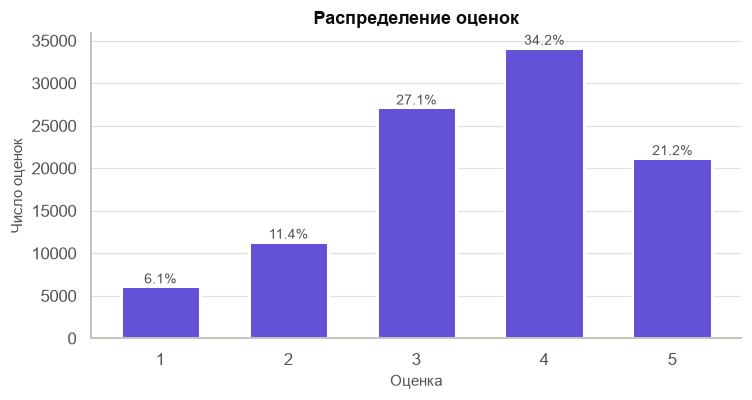

Средняя оценка: 3.530 | медиана: 4 | мода: 4 | стандартное отклонение: 1.126
Доля оценок 4 и 5: 55.4% | доля оценок 1 и 2: 17.5%


In [17]:
rating_counts = ratings['rating'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(rating_counts.index.astype(int).astype(str), rating_counts.values,
              color=C_RATING, width=0.62, edgecolor='white', linewidth=2)
for bar, share in zip(bars, rating_counts.values / n_ratings):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{share:.1%}',
            ha='center', va='bottom', color=INK_2, fontsize=9)
ax.set(title='Распределение оценок', xlabel='Оценка', ylabel='Число оценок')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print(f"Средняя оценка: {ratings['rating'].mean():.3f} | медиана: {ratings['rating'].median():.0f} | "
      f"мода: {ratings['rating'].mode()[0]:.0f} | стандартное отклонение: {ratings['rating'].std():.3f}")
print(f"Доля оценок 4 и 5: {(ratings['rating'] >= 4).mean():.1%} | доля оценок 1 и 2: {(ratings['rating'] <= 2).mean():.1%}")

Распределение смещено к положительным оценкам: «4» — самая частая (34,2 %), «4» и «5» вместе — 55,4 %, «1» — всего 6,1 %; средняя оценка — 3,53. Пользователи чаще оценивают то, что им заведомо интересно, поэтому низких оценок мало.

Следствия для моделей:
* предсказание одного лишь среднего уже ошибается в среднем почти на 1 звезду — это нижняя планка качества;
* все оценки положительные (1–5), поэтому косинусная мера на «сырых» оценках будет завышать сходство: векторы из положительных чисел почти всегда «смотрят» в одну сторону. Это проверяется на этапе 3.

### 2.3. Активность пользователей

In [18]:
user_stats = ratings.groupby('user_id')['rating'].agg(n_ratings='size', mean_rating='mean')
item_stats = ratings.groupby('item_id')['rating'].agg(n_ratings='size', mean_rating='mean')

describe = pd.concat({'Оценок на пользователя': user_stats['n_ratings'].describe(),
                      'Средняя оценка пользователя': user_stats['mean_rating'].describe(),
                      'Оценок на фильм': item_stats['n_ratings'].describe(),
                      'Средняя оценка фильма': item_stats['mean_rating'].describe()}, axis=1)
describe.index = ['Количество', 'Среднее', 'Ст. отклонение', 'Минимум', '25 %', 'Медиана', '75 %', 'Максимум']
describe.round(2)

,Оценок на пользователя,Средняя оценка пользователя,Оценок на фильм,Средняя оценка фильма
Количество,943.00,943.00,1682.00,1682.00
Среднее,106.04,3.59,59.45,3.08
Ст. отклонение,100.93,0.45,80.38,0.78
Минимум,20.00,1.49,1.00,1.00
25 %,33.00,3.32,6.00,2.66
Медиана,65.00,3.62,27.00,3.16
75 %,148.00,3.87,80.00,3.65
Максимум,737.00,4.87,583.00,5.00


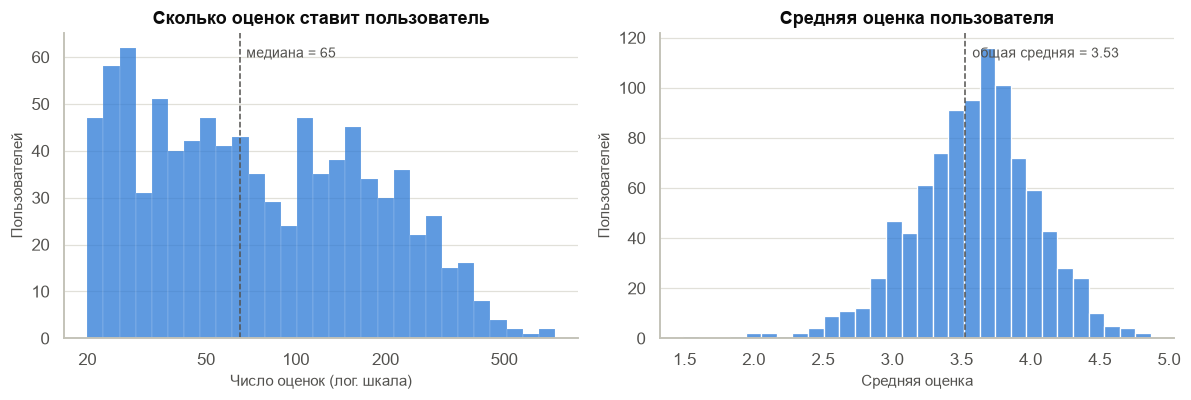

20 % самых активных пользователей дали 51.5% оценок; Джини = 0.47
Средние оценки пользователей: от 1.49 до 4.87; у 17.0% пользователей средняя ≥ 4, у 8.9% — ниже 3


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(user_stats['n_ratings'], bins=np.logspace(np.log10(20), np.log10(740), 30),
             color=C_USER, edgecolor='white', ax=axes[0])
axes[0].set_xscale('log')
axes[0].xaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
axes[0].xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
axes[0].set_xticks([20, 50, 100, 200, 500])
axes[0].axvline(user_stats['n_ratings'].median(), color=INK_2, ls='--', lw=1)
axes[0].text(user_stats['n_ratings'].median() * 1.05, axes[0].get_ylim()[1] * 0.92,
             f"медиана = {user_stats['n_ratings'].median():.0f}", color=INK_2, fontsize=9)
axes[0].set(title='Сколько оценок ставит пользователь', xlabel='Число оценок (лог. шкала)',
            ylabel='Пользователей')

sns.histplot(user_stats['mean_rating'], bins=30, color=C_USER, edgecolor='white', ax=axes[1])
axes[1].axvline(ratings['rating'].mean(), color=INK_2, ls='--', lw=1)
axes[1].text(ratings['rating'].mean() + 0.05, axes[1].get_ylim()[1] * 0.92,
             f"общая средняя = {ratings['rating'].mean():.2f}", color=INK_2, fontsize=9)
axes[1].set(title='Средняя оценка пользователя', xlabel='Средняя оценка', ylabel='Пользователей')
for ax in axes:
    ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()


def top_share(counts, share=0.2):
    """Доля всех оценок, приходящаяся на верхние `share` объектов."""
    c = np.sort(np.asarray(counts))[::-1]
    return c[:int(round(share * len(c)))].sum() / c.sum()


def gini(counts):
    """Коэффициент Джини: 0 — равномерно, 1 — всё у одного объекта."""
    c = np.sort(np.asarray(counts, dtype=float))
    n = len(c)
    return (2 * np.arange(1, n + 1) - n - 1).dot(c) / (n * c.sum())


print(f"20 % самых активных пользователей дали {top_share(user_stats['n_ratings']):.1%} оценок; "
      f"Джини = {gini(user_stats['n_ratings']):.2f}")
print(f"Средние оценки пользователей: от {user_stats['mean_rating'].min():.2f} до {user_stats['mean_rating'].max():.2f}; "
      f"у {(user_stats['mean_rating'] >= 4).mean():.1%} пользователей средняя ≥ 4, "
      f"у {(user_stats['mean_rating'] < 3).mean():.1%} — ниже 3")

**Активность неравномерна:** медиана — 65 оценок, среднее — 106, максимум — 737; пятая часть самых активных пользователей дала около половины всех оценок.

**Пользователи по-разному используют шкалу:** средние оценки различаются от «строгих» (около 1,5) до «щедрых» (около 4,9). Значит, «сырые» оценки разных пользователей несопоставимы: «3» у строгого пользователя может означать то же, что «5» у щедрого. Хорошей модели нужна нормализация — центрирование на среднюю оценку пользователя или учёт смещений. `KNNBasic` из примера задания её не выполняет.

### 2.4. Популярность фильмов

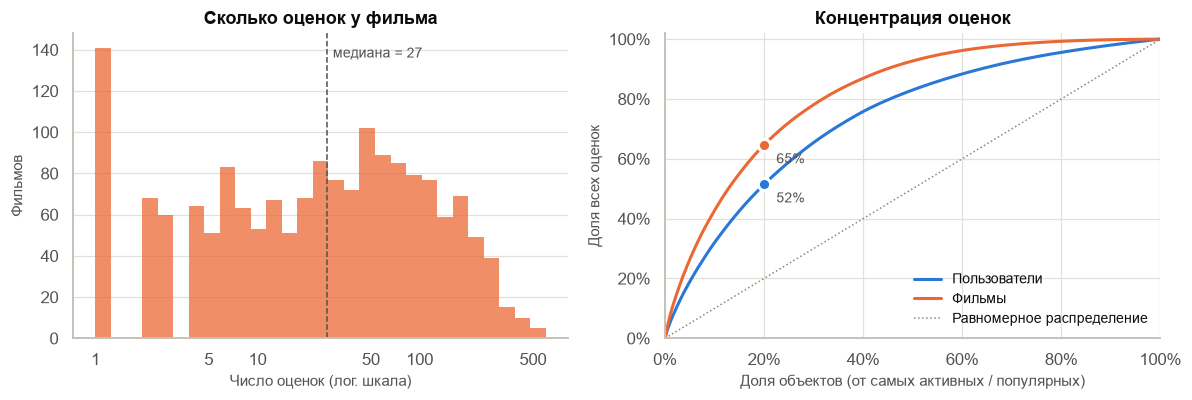

20 % самых популярных фильмов собрали 64.6% оценок; Джини = 0.63
Фильмов с 1 оценкой: 141 | меньше 5 оценок: 333 (19.8%) | меньше 10: 530 (31.5%)


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(item_stats['n_ratings'], bins=np.logspace(0, np.log10(600), 30),
             color=C_ITEM, edgecolor='white', ax=axes[0])
axes[0].set_xscale('log')
axes[0].xaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
axes[0].xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
axes[0].set_xticks([1, 5, 10, 50, 100, 500])
axes[0].axvline(item_stats['n_ratings'].median(), color=INK_2, ls='--', lw=1)
axes[0].text(item_stats['n_ratings'].median() * 1.08, axes[0].get_ylim()[1] * 0.92,
             f"медиана = {item_stats['n_ratings'].median():.0f}", color=INK_2, fontsize=9)
axes[0].set(title='Сколько оценок у фильма', xlabel='Число оценок (лог. шкала)', ylabel='Фильмов')
axes[0].grid(axis='x', visible=False)

# Кривая концентрации: какая доля оценок приходится на верхние X % пользователей / фильмов
for counts, color, label in [(user_stats['n_ratings'], C_USER, 'Пользователи'),
                             (item_stats['n_ratings'], C_ITEM, 'Фильмы')]:
    c = np.sort(counts.to_numpy())[::-1]
    x = np.arange(1, len(c) + 1) / len(c)
    y = np.cumsum(c) / c.sum()
    axes[1].plot(x, y, color=color, lw=2, label=label)
    y20 = top_share(c)
    axes[1].plot(0.2, y20, 'o', color=color, ms=8, mec='white', mew=2)
    axes[1].annotate(f'{y20:.0%}', (0.2, y20), xytext=(8, -12), textcoords='offset points',
                     color=INK_2, fontsize=9)
axes[1].plot([0, 1], [0, 1], color=C_BASE, ls=':', lw=1, label='Равномерное распределение')
axes[1].xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
axes[1].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
axes[1].set(title='Концентрация оценок', xlabel='Доля объектов (от самых активных / популярных)',
            ylabel='Доля всех оценок', xlim=(0, 1), ylim=(0, 1.02))
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"20 % самых популярных фильмов собрали {top_share(item_stats['n_ratings']):.1%} оценок; "
      f"Джини = {gini(item_stats['n_ratings']):.2f}")
print(f"Фильмов с 1 оценкой: {(item_stats['n_ratings'] == 1).sum()} | "
      f"меньше 5 оценок: {(item_stats['n_ratings'] < 5).sum()} ({(item_stats['n_ratings'] < 5).mean():.1%}) | "
      f"меньше 10: {(item_stats['n_ratings'] < 10).sum()} ({(item_stats['n_ratings'] < 10).mean():.1%})")

In [21]:
item_table = item_stats.join(movies.set_index('item_id')[['title', 'genres']])
item_table = item_table.rename(columns={'title': 'Фильм', 'genres': 'Жанры', 'n_ratings': 'Оценок',
                                        'mean_rating': 'Средняя'})
cols = ['Фильм', 'Жанры', 'Оценок', 'Средняя']

print('Самые популярные фильмы (по числу оценок):')
display(item_table.sort_values('Оценок', ascending=False)[cols].head(10).round(2))

print('Самые высоко оценённые фильмы среди имеющих не менее 100 оценок:')
display(item_table[item_table['Оценок'] >= 100].sort_values('Средняя', ascending=False)[cols].head(10).round(2))

print('Ловушка малых выборок: «лучшие» фильмы по средней оценке без порога по числу оценок:')
display(item_table.sort_values(['Средняя', 'Оценок'], ascending=[False, False])[cols].head(5).round(2))

Самые популярные фильмы (по числу оценок):


,Фильм,Жанры,Оценок,Средняя
item_id,,,,
50,Star Wars (1977),"Action, Adventure, Romance, Sci-Fi, War",583,4.36
258,Contact (1997),"Drama, Sci-Fi",509,3.80
100,Fargo (1996),"Crime, Drama, Thriller",508,4.16
181,Return of the Jedi (1983),"Action, Adventure, Romance, Sci-Fi, War",507,4.01
294,Liar Liar (1997),Comedy,485,3.16
286,"English Patient, The (1996)","Drama, Romance, War",481,3.66
288,Scream (1996),"Horror, Thriller",478,3.44
1,Toy Story (1995),"Animation, Children's, Comedy",452,3.88
300,Air Force One (1997),"Action, Thriller",431,3.63


Самые высоко оценённые фильмы среди имеющих не менее 100 оценок:


,Фильм,Жанры,Оценок,Средняя
item_id,,,,
408,"Close Shave, A (1995)","Animation, Comedy, Thriller",112,4.49
318,Schindler's List (1993),"Drama, War",298,4.47
169,"Wrong Trousers, The (1993)","Animation, Comedy",118,4.47
483,Casablanca (1942),"Drama, Romance, War",243,4.46
64,"Shawshank Redemption, The (1994)",Drama,283,4.45
603,Rear Window (1954),"Mystery, Thriller",209,4.39
12,"Usual Suspects, The (1995)","Crime, Thriller",267,4.39
50,Star Wars (1977),"Action, Adventure, Romance, Sci-Fi, War",583,4.36
178,12 Angry Men (1957),Drama,125,4.34


Ловушка малых выборок: «лучшие» фильмы по средней оценке без порога по числу оценок:


,Фильм,Жанры,Оценок,Средняя
item_id,,,,
1189,Prefontaine (1997),Drama,3,5.0
1293,Star Kid (1997),"Adventure, Children's, Fantasy, Sci-Fi",3,5.0
1467,"Saint of Fort Washington, The (1993)",Drama,2,5.0
1500,Santa with Muscles (1996),Comedy,2,5.0
814,"Great Day in Harlem, A (1994)",Documentary,1,5.0


**«Длинный хвост»:** медиана — 27 оценок на фильм, у 141 фильма всего одна оценка, почти у трети фильмов — меньше 10. 20 % самых популярных фильмов собрали около 65 % всех оценок; концентрация по фильмам сильнее, чем по пользователям.

**Популярные фильмы** — «Звёздные войны» и хиты 1996–1997 годов («Контакт», «Фарго», «Лжец, лжец», «Крик»). Среди фильмов с не менее чем 100 оценками выше всех оценены признанные шедевры («Список Шиндлера», «Касабланка», «Побег из Шоушенка», «Окно во двор») и короткометражки об Уоллесе и Громите. Популярность и высокая оценка совпадают не всегда: «Лжец, лжец» и «Крик» много смотрели, но оценили средне (3,2–3,4).

**Ловушка малых выборок:** средняя оценка 5,0 у фильмов с 1–3 оценками ничего не говорит об их качестве. Та же проблема проявится в рекомендациях на этапе 5.

### 2.5. Анализ разреженности с точки зрения KNN: число общих оценок у пар
KNN-модели вычисляют сходство только по **общим** оценкам: сходство двух пользователей — по фильмам, которые оценили оба, сходство двух фильмов — по пользователям, которые оценили оба. Поэтому для KNN важна не только общая разреженность матрицы, но и **поддержка** (support) — число общих оценок у пары. Чем она меньше, тем случайнее значение сходства.

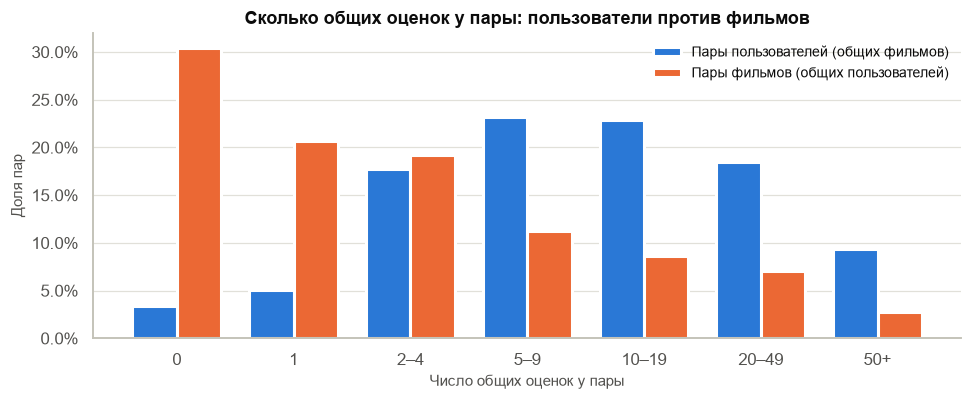

,Пар всего,Нет общих оценок,Ровно 1 общая,Меньше 5 общих,Медиана общих,Среднее общих
Пары пользователей,444 153,3.4%,5.0%,26.2%,10.0,18.8
Пары фильмов,1 413 721,30.5%,20.7%,70.3%,1.0,7.1


In [22]:
assert ratings['user_id'].max() == n_users and ratings['item_id'].max() == n_items  # ID идут подряд с 1
R = sp.csr_matrix((np.ones(n_ratings), (ratings['user_id'] - 1, ratings['item_id'] - 1)), shape=(n_users, n_items))

common_users = (R @ R.T).toarray()[np.triu_indices(n_users, k=1)]   # общих фильмов у пары пользователей
common_items = (R.T @ R).toarray()[np.triu_indices(n_items, k=1)]   # общих пользователей у пары фильмов

support_bins = [0, 1, 2, 5, 10, 20, 50, np.inf]
support_labels = ['0', '1', '2–4', '5–9', '10–19', '20–49', '50+']


def support_shares(common):
    return pd.Series(pd.cut(common, support_bins, labels=support_labels, right=False)) \
        .value_counts(normalize=True).sort_index()


shares = pd.DataFrame({'Пары пользователей': support_shares(common_users),
                       'Пары фильмов': support_shares(common_items)})

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(support_labels))
w = 0.38
ax.bar(x - w / 2, shares['Пары пользователей'], w, color=C_USER, edgecolor='white', linewidth=2,
       label='Пары пользователей (общих фильмов)')
ax.bar(x + w / 2, shares['Пары фильмов'], w, color=C_ITEM, edgecolor='white', linewidth=2,
       label='Пары фильмов (общих пользователей)')
ax.set_xticks(x, support_labels)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
ax.set(title='Сколько общих оценок у пары: пользователи против фильмов',
       xlabel='Число общих оценок у пары', ylabel='Доля пар')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

support_summary = pd.DataFrame({
    'Пар всего': [fmt_int(len(common_users)), fmt_int(len(common_items))],
    'Нет общих оценок': [f'{(common_users == 0).mean():.1%}', f'{(common_items == 0).mean():.1%}'],
    'Ровно 1 общая': [f'{(common_users == 1).mean():.1%}', f'{(common_items == 1).mean():.1%}'],
    'Меньше 5 общих': [f'{(common_users < 5).mean():.1%}', f'{(common_items < 5).mean():.1%}'],
    'Медиана общих': [np.median(common_users), np.median(common_items)],
    'Среднее общих': [round(common_users.mean(), 1), round(common_items.mean(), 1)],
}, index=['Пары пользователей', 'Пары фильмов'])
support_summary

**Главный результат анализа разреженности.** У пар пользователей медиана — 10 общих фильмов, и лишь у 3,4 % пар пересечений нет. У пар фильмов медиана — **1** общий пользователь: у 30,5 % пар пересечений нет вовсе, у 70 % их меньше пяти. Значит, сходство фильмов в `ml-100k` в большинстве случаев вычисляется по 1–4 оценкам и поэтому шумное. Это следствие формы матрицы: пользователей (943) меньше, чем фильмов (1 682), и на пользователя приходится в среднем 106 оценок, а на фильм — 59,5.

### Выводы EDA
1. Матрица разрежена на **93,7 %** — задача рекомендаций сводится к заполнению пропусков по небольшой известной части.
2. Оценки смещены вверх (среднее 3,53), а пользователи по-разному используют шкалу — без нормализации «сырые» оценки разных людей несопоставимы.
3. Активность пользователей и популярность фильмов распределены неравномерно, у фильмов — выраженный «длинный хвост»: 141 фильм с одной оценкой.
4. Поддержка сходства у пар пользователей заметно выше, чем у пар фильмов. Гипотеза: в базовой конфигурации User-based окажется точнее Item-based, а обе модели будут страдать от шумных сходств, посчитанных по одной-двум оценкам.

## Этап 3. Реализация моделей
Обе модели — `KNNBasic` из `surprise` с косинусной мерой, как в примере задания; различается только объект сравнения.

**User-based** — оценку пользователя $u$ фильму $i$ предсказывают по оценкам похожих пользователей:
$$\hat r_{ui} = \frac{\sum_{v \in N_i^k(u)} \text{sim}(u, v)\, r_{vi}}{\sum_{v \in N_i^k(u)} \text{sim}(u, v)},$$
где $N_i^k(u)$ — $k$ самых похожих на $u$ пользователей среди тех, кто оценил фильм $i$.

**Item-based** — по оценкам, которые сам пользователь $u$ поставил похожим фильмам:
$$\hat r_{ui} = \frac{\sum_{j \in N_u^k(i)} \text{sim}(i, j)\, r_{uj}}{\sum_{j \in N_u^k(i)} \text{sim}(i, j)},$$
где $N_u^k(i)$ — $k$ фильмов, самых похожих на $i$, среди оценённых пользователем $u$.

**Косинусная мера** считается только по общим оценкам $I_{uv}$:
$$\text{sim}(u, v) = \frac{\sum_{i \in I_{uv}} r_{ui}\, r_{vi}}{\sqrt{\sum_{i \in I_{uv}} r_{ui}^2}\,\sqrt{\sum_{i \in I_{uv}} r_{vi}^2}}.$$

Параметры по умолчанию: `k = 40` соседей, `min_k = 1` (достаточно одного соседа). Если соседей нет, модель возвращает глобальное среднее и помечает прогноз как `was_impossible`. Важная деталь: при **одной** общей оценке косинус всегда равен 1 — вектор из одного положительного числа совпадает по направлению с любым другим таким же.

In [23]:
# User-based: поиск похожих пользователей
sim_options_user = {'name': 'cosine', 'user_based': True}
model_user = KNNBasic(k=40, min_k=1, sim_options=sim_options_user, verbose=False)

# Item-based: поиск похожих фильмов
sim_options_item = {'name': 'cosine', 'user_based': False}
model_item = KNNBasic(k=40, min_k=1, sim_options=sim_options_item, verbose=False)

print(model_user.__class__.__name__, model_user.sim_options)
print(model_item.__class__.__name__, model_item.sim_options)

KNNBasic {'name': 'cosine', 'user_based': True}
KNNBasic {'name': 'cosine', 'user_based': False}


### 3.1. Что «видят» модели: диагностика матриц сходства
Обучим обе модели на всех данных и посмотрим на полученные матрицы сходства вместе с поддержкой каждой пары. Эти же обученные модели используются на этапе 5 для рекомендаций.

In [24]:
full_trainset = data.build_full_trainset()
full_user = KNNBasic(k=40, min_k=1, sim_options=sim_options_user, verbose=False).fit(full_trainset)
full_item = KNNBasic(k=40, min_k=1, sim_options=sim_options_item, verbose=False).fit(full_trainset)

# Поддержка (число общих оценок) в порядке внутренних ID surprise
pairs = np.array([(u, i) for u, i, _ in full_trainset.all_ratings()])
B = sp.csr_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])),
                  shape=(full_trainset.n_users, full_trainset.n_items))
support_uu, support_ii = (B @ B.T).toarray(), (B.T @ B).toarray()

diag = {}
for name, model, support in [('User-based', full_user, support_uu), ('Item-based', full_item, support_ii)]:
    iu = np.triu_indices(model.sim.shape[0], k=1)
    diag[name] = pd.DataFrame({'sim': model.sim[iu], 'support': support[iu]})
    print(f'{name}: матрица сходства {model.sim.shape[0]} × {model.sim.shape[1]}')

sim_summary = pd.DataFrame({
    name: {
        'Пар с общими оценками': f"{(d['support'] > 0).mean():.1%}",
        'Среднее сходство (при общих оценках)': f"{d.loc[d['support'] > 0, 'sim'].mean():.3f}",
        'Доля пар со сходством > 0,9': f"{(d.loc[d['support'] > 0, 'sim'] > 0.9).mean():.1%}",
        'Доля пар со сходством = 1': f"{np.isclose(d.loc[d['support'] > 0, 'sim'], 1).mean():.1%}",
        '…из них с одной общей оценкой': f"{(d.loc[np.isclose(d['sim'], 1) & (d['support'] > 0), 'support'] == 1).mean():.1%}",
    } for name, d in diag.items()})
sim_summary

User-based: матрица сходства 943 × 943
Item-based: матрица сходства 1682 × 1682


,User-based,Item-based
Пар с общими оценками,96.6%,69.5%
Среднее сходство (при общих оценках),0.945,0.950
"Доля пар со сходством > 0,9",87.2%,84.1%
Доля пар со сходством = 1,6.5%,32.3%
…из них с одной общей оценкой,80.7%,92.3%


User-based: пар со сходством ниже 0,7 — 0.22%
Item-based: пар со сходством ниже 0,7 — 0.61%


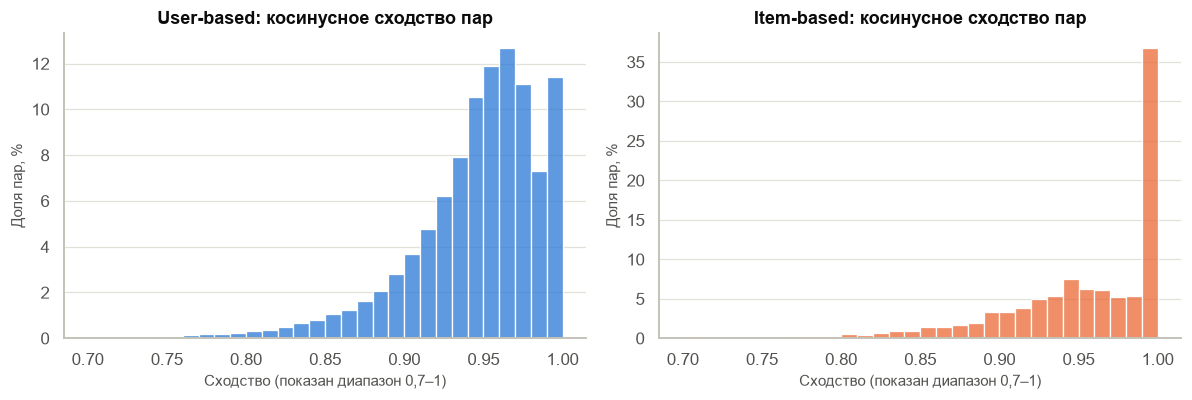

User-based                    Item-based             
                    Среднее сходство Доля sim = 1 Среднее сходство Доля sim = 1
Общих оценок у пары                                                            
1                              1.000        1.000            1.000        1.000
2–4                            0.947        0.066            0.934        0.090
5–9                            0.938        0.001            0.920        0.001
10–19                          0.939        0.000            0.924        0.000
20–49                          0.942        0.000            0.933        0.000
50+                            0.944        0.000            0.943        0.000

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, (name, d), color in zip(axes, diag.items(), [C_USER, C_ITEM]):
    s = d.loc[d['support'] > 0, 'sim']
    sns.histplot(s, bins=30, binrange=(0.7, 1), stat='percent', color=color, edgecolor='white', ax=ax)
    ax.set(title=f'{name}: косинусное сходство пар', xlabel='Сходство (показан диапазон 0,7–1)',
           ylabel='Доля пар, %')
    ax.grid(axis='x', visible=False)
    print(f'{name}: пар со сходством ниже 0,7 — {(s < 0.7).mean():.2%}')
plt.tight_layout()
plt.show()

# Как сходство зависит от поддержки пары
by_support = pd.concat({
    name: d[d['support'] > 0].groupby(pd.cut(d.loc[d['support'] > 0, 'support'], support_bins[1:],
                                             labels=support_labels[1:], right=False), observed=True)['sim']
           .agg(**{'Среднее сходство': 'mean', 'Доля sim = 1': lambda s: np.isclose(s, 1).mean()})
    for name, d in diag.items()}, axis=1).round(3)
by_support.index.name = 'Общих оценок у пары'
by_support

**Что показывает диагностика:**
* **Косинус на «сырых» оценках почти не различает соседей.** Среднее сходство пар — около 0,95, у 84–87 % пар оно выше 0,9, и даже при 50+ общих оценках остаётся на уровне 0,94. Причина — оценки 1–5 положительны и не центрированы, поэтому векторы любых двух пользователей (или фильмов) направлены почти одинаково. Фактически `KNNBasic` с косинусом усредняет оценки почти случайных 40 соседей.
* **При одной общей оценке сходство всегда равно 1.** Это 6,5 % пар пользователей и 32 % пар фильмов (среди пар с общими оценками); у фильмов более 90 % всех пар с идеальным сходством «совпали» по одному-единственному зрителю. Такие пары становятся самыми близкими соседями — это шум, порождённый разреженностью.

Ожидание: обе модели будут заметно уступать тому, что можно извлечь из данных; Item-based пострадает сильнее из-за меньшей поддержки сходств. Проверяем кросс-валидацией.

## Этап 4. Кросс-валидация и оценка качества
### 4.1. Сравнение User-based и Item-based на 5 фолдах
Для честного **парного** сравнения все модели оцениваются на одних и тех же фолдах: объект `KFold` с фиксированным `random_state` при каждом вызове делит данные одинаково. В каждом фолде 80 000 оценок — обучение, 20 000 — тест.

In [26]:
kf = KFold(n_splits=5, random_state=SEED, shuffle=True)

print('Результаты User-based CF:')
cv_user = cross_validate(model_user, data, measures=['RMSE', 'MAE'], cv=kf, verbose=True)

print('\nРезультаты Item-based CF:')
cv_item = cross_validate(model_item, data, measures=['RMSE', 'MAE'], cv=kf, verbose=True)

Результаты User-based CF:
Evaluating RMSE, MAE of algorithm KNNBasic on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    1.0120  1.0117  1.0239  1.0184  1.0194  1.0171  0.0047  
MAE (testset)     0.7984  0.8008  0.8123  0.8066  0.8038  0.8044  0.0048  
Fit time          1.53    1.30    1.31    1.29    1.26    1.34    0.10    
Test time         2.42    2.28    2.29    2.28    2.45    2.34    0.08    

Результаты Item-based CF:
Evaluating RMSE, MAE of algorithm KNNBasic on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    1.0234  1.0238  1.0316  1.0226  1.0264  1.0255  0.0033  
MAE (testset)     0.8095  0.8081  0.8182  0.8089  0.8104  0.8110  0.0037  
Fit time          1.91    1.92    1.58    1.55    1.58    1.71    0.17    
Test time         2.81    2.59    2.29    2.18    2.16    2.40    0.25    


In [27]:
folds = pd.DataFrame({
    'Фолд': np.arange(1, 6),
    'RMSE · User-based': cv_user['test_rmse'], 'RMSE · Item-based': cv_item['test_rmse'],
    'MAE · User-based': cv_user['test_mae'], 'MAE · Item-based': cv_item['test_mae'],
}).set_index('Фолд')
folds['Δ RMSE (User − Item)'] = folds['RMSE · User-based'] - folds['RMSE · Item-based']
folds['Δ MAE (User − Item)'] = folds['MAE · User-based'] - folds['MAE · Item-based']
folds.loc['Среднее'] = folds.iloc[:5].mean()
folds.loc['Ст. отклонение'] = folds.iloc[:5].std(ddof=0)   # ddof=0 — как в отчёте cross_validate
display(folds.round(4))

wins_rmse = int((cv_user['test_rmse'] < cv_item['test_rmse']).sum())
wins_mae = int((cv_user['test_mae'] < cv_item['test_mae']).sum())
d_rmse = cv_user['test_rmse'] - cv_item['test_rmse']
print(f'User-based точнее Item-based по RMSE на {wins_rmse} из 5 фолдов, по MAE — на {wins_mae} из 5.')
print(f'Средняя разница RMSE {d_rmse.mean():.4f} в {abs(d_rmse.mean()) / d_rmse.std():.1f} раза больше '
      f'её разброса между фолдами ({d_rmse.std():.4f}).')
print(f"Среднее время обучения: User-based {np.mean(cv_user['fit_time']):.2f} с, "
      f"Item-based {np.mean(cv_item['fit_time']):.2f} с; "
      f"предсказания 20 000 оценок: {np.mean(cv_user['test_time']):.2f} с и {np.mean(cv_item['test_time']):.2f} с.")

,RMSE · User-based,RMSE · Item-based,MAE · User-based,MAE · Item-based,Δ RMSE (User − Item),Δ MAE (User − Item)
Фолд,,,,,,
1,1.0120,1.0234,0.7984,0.8095,-0.0115,-0.0111
2,1.0117,1.0238,0.8008,0.8081,-0.0120,-0.0073
3,1.0239,1.0316,0.8123,0.8182,-0.0076,-0.0059
4,1.0184,1.0226,0.8066,0.8089,-0.0041,-0.0023
5,1.0194,1.0264,0.8038,0.8104,-0.0071,-0.0066
Среднее,1.0171,1.0255,0.8044,0.8110,-0.0085,-0.0066
Ст. отклонение,0.0047,0.0033,0.0048,0.0037,0.0029,0.0028


User-based точнее Item-based по RMSE на 5 из 5 фолдов, по MAE — на 5 из 5.
Средняя разница RMSE -0.0085 в 2.9 раза больше её разброса между фолдами (0.0029).
Среднее время обучения: User-based 1.34 с, Item-based 1.71 с; предсказания 20 000 оценок: 2.34 с и 2.40 с.


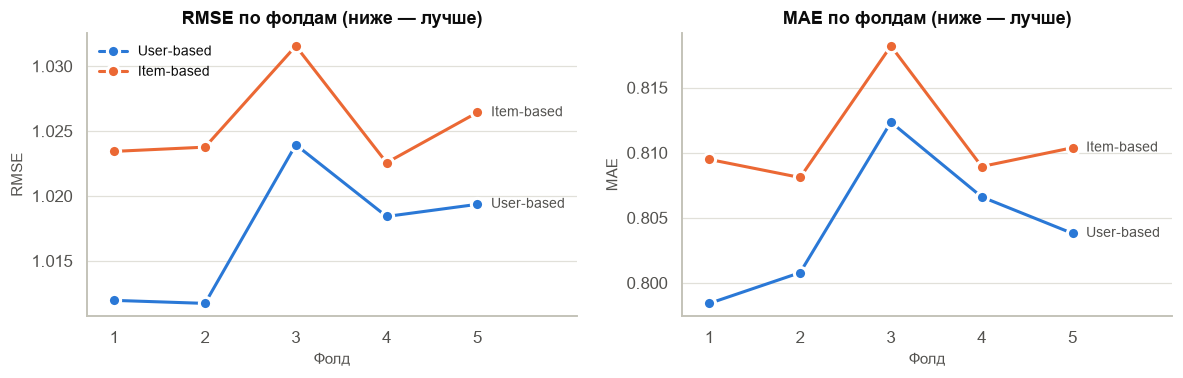

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, metric in zip(axes, ['RMSE', 'MAE']):
    key = f'test_{metric.lower()}'
    for res, color, label in [(cv_user, C_USER, 'User-based'), (cv_item, C_ITEM, 'Item-based')]:
        ax.plot(range(1, 6), res[key], marker='o', ms=8, mec='white', mew=2, lw=2, color=color, label=label)
        ax.text(5.15, res[key][-1], label, color=INK_2, fontsize=9, va='center')
    ax.set(title=f'{metric} по фолдам (ниже — лучше)', xlabel='Фолд', ylabel=metric, xlim=(0.7, 6.1))
    ax.set_xticks(range(1, 6))
    ax.grid(axis='x', visible=False)
axes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()

**Результат базового сравнения:** User-based точнее Item-based — в среднем RMSE 1,0171 против 1,0255 и MAE 0,8044 против 0,8110, причём User-based выигрывает на **каждом** из 5 фолдов по обеим метрикам. Разница невелика (≈ 0,008 звезды по RMSE), но устойчива: она почти в 3 раза больше своего разброса между фолдами. Это согласуется с анализом разреженности: сходство пользователей опирается на большее число общих оценок, чем сходство фильмов.

В абсолютных величинах обе модели ошибаются в среднем примерно на 0,8 звезды (MAE), а с учётом крупных промахов — примерно на 1 звезду (RMSE). Обе модели быстрые: обучение (расчёт матрицы сходства) занимает доли секунды, Item-based — примерно вдвое дольше из-за большей матрицы (1 682 × 1 682 против 943 × 943).

### 4.2. Ручной расчёт RMSE и MAE и анализ ошибок
Пересчитаем метрики «вручную» на первом фолде и сверим с `surprise.accuracy` и с результатом кросс-валидации.

In [29]:
trainset_1, testset_1 = next(kf.split(data))   # тот же первый фолд, что и в cross_validate


def rmse_manual(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))


def mae_manual(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))


manual_rows, errors = [], {}
for name, sim_options, cv_res in [('User-based', sim_options_user, cv_user), ('Item-based', sim_options_item, cv_item)]:
    algo = KNNBasic(k=40, min_k=1, sim_options=sim_options, verbose=False).fit(trainset_1)
    preds = algo.test(testset_1)
    y_true = np.array([p.r_ui for p in preds])
    y_pred = np.array([p.est for p in preds])
    errors[name] = pd.DataFrame({'item_id': [int(p.iid) for p in preds], 'r': y_true, 'est': y_pred,
                                 'impossible': [p.details.get('was_impossible', False) for p in preds]})
    manual_rows.append({
        'Модель': name,
        'RMSE вручную': rmse_manual(y_true, y_pred), 'RMSE surprise.accuracy': accuracy.rmse(preds, verbose=False),
        'RMSE фолд 1 в CV': cv_res['test_rmse'][0],
        'MAE вручную': mae_manual(y_true, y_pred), 'MAE surprise.accuracy': accuracy.mae(preds, verbose=False),
        'MAE фолд 1 в CV': cv_res['test_mae'][0],
        'RMSE / MAE': rmse_manual(y_true, y_pred) / mae_manual(y_true, y_pred),
        'Прогнозов без соседей': np.mean(errors[name]['impossible']),
    })

manual = pd.DataFrame(manual_rows).set_index('Модель')
assert np.allclose(manual['RMSE вручную'], manual['RMSE surprise.accuracy'])
assert np.allclose(manual['MAE вручную'], manual['MAE surprise.accuracy'])
assert np.allclose(manual['RMSE вручную'], manual['RMSE фолд 1 в CV'])
print('Ручной расчёт совпадает с surprise.accuracy и с результатом cross_validate.')
manual.round(4)

Ручной расчёт совпадает с surprise.accuracy и с результатом cross_validate.


,RMSE вручную,RMSE surprise.accuracy,RMSE фолд 1 в CV,MAE вручную,MAE surprise.accuracy,MAE фолд 1 в CV,RMSE / MAE,Прогнозов без соседей
Модель,,,,,,,,
User-based,1.0120,1.0120,1.0120,0.7984,0.7984,0.7984,1.2674,0.0016
Item-based,1.0234,1.0234,1.0234,0.8095,0.8095,0.8095,1.2643,0.0016


In [30]:
# Ошибка в зависимости от истинной оценки: модели «стягивают» прогнозы к среднему
by_rating = pd.concat({
    name: e.assign(err=e['est'] - e['r']).groupby('r')
           .agg(**{'Средний прогноз': ('est', 'mean'), 'MAE': ('err', lambda s: s.abs().mean())})
    for name, e in errors.items()}, axis=1).round(3)
by_rating.index = by_rating.index.astype(int)
by_rating.index.name = 'Истинная оценка'
display(by_rating)
for name, e in errors.items():
    print(f"{name}: разброс прогнозов (std) = {e['est'].std():.2f} при разбросе истинных оценок {e['r'].std():.2f}")

User-based             Item-based       
                Средний прогноз    MAE Средний прогноз    MAE
Истинная оценка                                              
1                         3.091  2.091           3.022  2.022
2                         3.276  1.287           3.319  1.339
3                         3.506  0.618           3.481  0.561
4                         3.747  0.397           3.670  0.415
5                         3.954  1.046           3.863  1.137

User-based: разброс прогнозов (std) = 0.56 при разбросе истинных оценок 1.12
Item-based: разброс прогнозов (std) = 0.53 при разбросе истинных оценок 1.12


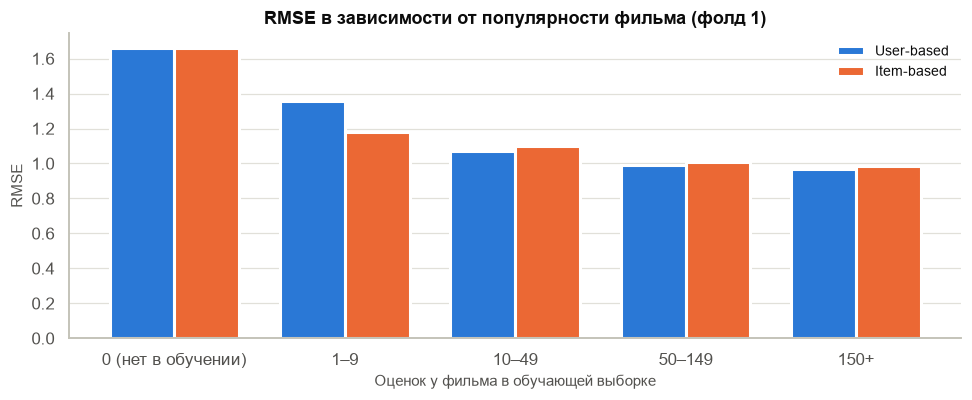

,User-based,Item-based,Тестовых оценок
item_id,,,
0 (нет в обучении),1.663,1.663,31
1–9,1.356,1.182,599
10–49,1.073,1.098,3663
50–149,0.990,1.006,8471
150+,0.967,0.986,7236


In [31]:
# Ошибка в зависимости от популярности фильма в обучающей выборке
train_pop = pd.Series({int(trainset_1.to_raw_iid(i)): len(r) for i, r in trainset_1.ir.items()})
pop_bins, pop_labels = [-1, 0, 9, 49, 149, np.inf], ['0 (нет в обучении)', '1–9', '10–49', '50–149', '150+']

by_pop = {}
for name, e in errors.items():
    bucket = pd.cut(e['item_id'].map(train_pop).fillna(0), pop_bins, labels=pop_labels)
    by_pop[name] = e.assign(sq=(e['est'] - e['r']) ** 2).groupby(bucket, observed=False)['sq'].mean() ** 0.5
by_pop = pd.DataFrame(by_pop)
by_pop['Тестовых оценок'] = pd.cut(errors['User-based']['item_id'].map(train_pop).fillna(0),
                                   pop_bins, labels=pop_labels).value_counts().reindex(pop_labels).values

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(pop_labels))
w = 0.38
for shift, name, color in [(-w / 2, 'User-based', C_USER), (w / 2, 'Item-based', C_ITEM)]:
    ax.bar(x + shift, by_pop[name], w, color=color, edgecolor='white', linewidth=2, label=name)
ax.set_xticks(x, pop_labels)
ax.set(title='RMSE в зависимости от популярности фильма (фолд 1)',
       xlabel='Оценок у фильма в обучающей выборке', ylabel='RMSE')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()
by_pop.round(3)

**Интерпретация метрик:**
* Ручной расчёт совпадает с `surprise.accuracy` и с первым фолдом кросс-валидации до последнего знака — метрики посчитаны корректно.
* RMSE ≈ 1,02 при MAE ≈ 0,80: отношение RMSE/MAE ≈ 1,27 близко к значению $\sqrt{\pi/2} \approx 1{,}25$ для нормально распределённых ошибок — ошибки в основном умеренные, без большого числа катастрофических промахов.
* Обе модели **«стягивают» прогнозы к среднему**: разброс прогнозов вдвое меньше разброса настоящих оценок. «Единицам» модели ставят в среднем около 3, «пятёркам» — около 3,9, поэтому ошибка на крайних оценках («1», «2», «5») в 2,5–5 раз больше, чем на «четвёрках».
* **Популярность фильма определяет точность.** У обеих моделей ошибка растёт к «хвосту». На редких фильмах (1–9 оценок в обучении) Item-based заметно точнее User-based (RMSE 1,18 против 1,36): она опирается на оценки самого пользователя, а User-based — на одного-двух случайных соседей. Но фильмы с 50+ оценками дают 79 % тестовых оценок, и на них немного точнее User-based — это и решает исход среднего RMSE.

### 4.3. Сравнение с бейзлайнами и классификация моделей по KPI
Чтобы понять, хороша ли модель **в принципе**, а не только относительно соседней, сравним её с бейзлайнами из KPI и с улучшенными вариантами тех же двух подходов. Каждый вариант меняет ровно один элемент:

| Изменение | Что исправляет |
|---|---|
| `msd` вместо `cosine` | мера сходства по среднеквадратичной разнице оценок — различает соседей лучше косинуса на положительных оценках |
| `min_k = 5` | прогноз только при наличии ≥ 5 соседей, иначе — глобальное среднее (защита от прогнозов по 1–2 соседям) |
| `min_support = 5` | сходство пары считается, только если у неё ≥ 5 общих оценок (защита от шумных sim = 1) |
| `KNNWithMeans` | центрирование: усредняются отклонения соседей от их средних оценок, а не «сырые» оценки |
| `KNNBaseline` + `pearson_baseline` | учёт смещений $b_u, b_i$ и корреляция с усадкой (`shrinkage = 100`) для пар с малой поддержкой |
| `SVD` | матричная факторизация (model-based CF) — ориентир «современного» подхода |

In [32]:
class GlobalMean(AlgoBase):
    """Наивный бейзлайн: каждой паре предсказывает среднюю оценку обучающей выборки."""

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        return self

    def estimate(self, u, i):
        return self.trainset.global_mean


def knn(algo_cls, approach, sim='cosine', **params):
    sim_options = {'name': sim, 'user_based': approach == 'User-based'}
    sim_options.update({k: v for k, v in params.items() if k in ('min_support', 'shrinkage')})
    algo_params = {k: v for k, v in params.items() if k not in ('min_support', 'shrinkage')}
    return algo_cls(sim_options=sim_options, verbose=False, **algo_params)


experiments = [
    # (название, подход, алгоритм)
    ('Глобальное среднее', 'Бейзлайн', GlobalMean()),
    ('NormalPredictor (случайный)', 'Бейзлайн', NormalPredictor()),
    ('BaselineOnly (μ + b_u + b_i)', 'Бейзлайн', BaselineOnly(verbose=False)),
    ('KNNBasic · msd', 'User-based', knn(KNNBasic, 'User-based', 'msd')),
    ('KNNBasic · msd', 'Item-based', knn(KNNBasic, 'Item-based', 'msd')),
    ('KNNBasic · cosine · min_k=5', 'User-based', knn(KNNBasic, 'User-based', min_k=5)),
    ('KNNBasic · cosine · min_support=5', 'Item-based', knn(KNNBasic, 'Item-based', min_support=5)),
    ('KNNWithMeans · cosine', 'User-based', knn(KNNWithMeans, 'User-based')),
    ('KNNWithMeans · cosine', 'Item-based', knn(KNNWithMeans, 'Item-based')),
    ('KNNBaseline · pearson_baseline', 'User-based', knn(KNNBaseline, 'User-based', 'pearson_baseline')),
    ('KNNBaseline · pearson_baseline', 'Item-based', knn(KNNBaseline, 'Item-based', 'pearson_baseline')),
    ('SVD (матричная факторизация)', 'Model-based', SVD(random_state=SEED)),
]

cv_results = {('KNNBasic · cosine (задание)', 'User-based'): cv_user,
              ('KNNBasic · cosine (задание)', 'Item-based'): cv_item}
for name, approach, algo in experiments:
    cv_results[(name, approach)] = cross_validate(algo, data, measures=['RMSE', 'MAE'], cv=kf)
    print(f"{approach:11s} | {name:35s} RMSE = {cv_results[(name, approach)]['test_rmse'].mean():.4f}")

Бейзлайн    | Глобальное среднее                  RMSE = 1.1257
Бейзлайн    | NormalPredictor (случайный)         RMSE = 1.5210
Бейзлайн    | BaselineOnly (μ + b_u + b_i)        RMSE = 0.9436
User-based  | KNNBasic · msd                      RMSE = 0.9789
Item-based  | KNNBasic · msd                      RMSE = 0.9733
User-based  | KNNBasic · cosine · min_k=5         RMSE = 1.0172
Item-based  | KNNBasic · cosine · min_support=5   RMSE = 1.0346
User-based  | KNNWithMeans · cosine               RMSE = 0.9547
Item-based  | KNNWithMeans · cosine               RMSE = 0.9421
User-based  | KNNBaseline · pearson_baseline      RMSE = 0.9215
Item-based  | KNNBaseline · pearson_baseline      RMSE = 0.9155
Model-based | SVD (матричная факторизация)        RMSE = 0.9350


In [33]:
base = cv_results[('BaselineOnly (μ + b_u + b_i)', 'Бейзлайн')]
naive = cv_results[('Глобальное среднее', 'Бейзлайн')]


def kpi_class(res):
    rmse, mae = res['test_rmse'], res['test_mae']
    if rmse.mean() >= naive['test_rmse'].mean():
        return 'Бесполезна'
    if (rmse < base['test_rmse']).all() and (mae < base['test_mae']).all():
        return 'Эффективна'
    if rmse.mean() < base['test_rmse'].mean() or mae.mean() < base['test_mae'].mean():
        return 'Пограничная'
    return 'Неэффективна'


rows = []
for (name, approach), res in cv_results.items():
    rows.append({
        'Подход': approach, 'Модель': name,
        'RMSE': res['test_rmse'].mean(), 'RMSE std': res['test_rmse'].std(),
        'MAE': res['test_mae'].mean(), 'MAE std': res['test_mae'].std(),
        'Фолдов лучше BaselineOnly (RMSE)': int((res['test_rmse'] < base['test_rmse']).sum()),
        'Улучшение RMSE к глоб. среднему': 1 - res['test_rmse'].mean() / naive['test_rmse'].mean(),
        'Обучение, с': np.mean(res['fit_time']),
        'KPI': '—' if approach == 'Бейзлайн' else kpi_class(res),
    })
leaderboard = pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
leaderboard.index += 1
(leaderboard.style
 .format({'RMSE': '{:.4f}', 'RMSE std': '{:.4f}', 'MAE': '{:.4f}', 'MAE std': '{:.4f}',
          'Улучшение RMSE к глоб. среднему': '{:.1%}', 'Обучение, с': '{:.2f}'})
 .apply(lambda r: ['font-weight: bold' if 'задание' in r['Модель'] else '' for _ in r], axis=1))

,Подход,Модель,RMSE,RMSE std,MAE,MAE std,Фолдов лучше BaselineOnly (RMSE),Улучшение RMSE к глоб. среднему,"Обучение, с",KPI
1,Item-based,KNNBaseline · pearson_baseline,0.9155,0.0038,0.7182,0.0033,5,18.7%,1.79,Эффективна
2,User-based,KNNBaseline · pearson_baseline,0.9215,0.0036,0.7210,0.0031,5,18.1%,1.28,Эффективна
3,Model-based,SVD (матричная факторизация),0.9350,0.0036,0.7372,0.0026,5,16.9%,0.77,Эффективна
4,Item-based,KNNWithMeans · cosine,0.9421,0.0030,0.7409,0.0023,4,16.3%,1.54,Пограничная
5,Бейзлайн,BaselineOnly (μ + b_u + b_i),0.9436,0.0037,0.7481,0.0036,0,16.2%,0.18,—
6,User-based,KNNWithMeans · cosine,0.9547,0.0035,0.7540,0.0037,0,15.2%,1.21,Неэффективна
7,Item-based,KNNBasic · msd,0.9733,0.0033,0.7692,0.0034,0,13.5%,0.62,Неэффективна
8,User-based,KNNBasic · msd,0.9789,0.0041,0.7735,0.0041,0,13.0%,0.42,Неэффективна
9,User-based,KNNBasic · cosine (задание),1.0171,0.0047,0.8044,0.0048,0,9.6%,1.34,Неэффективна
10,User-based,KNNBasic · cosine · min_k=5,1.0172,0.0049,0.8052,0.0045,0,9.6%,1.03,Неэффективна


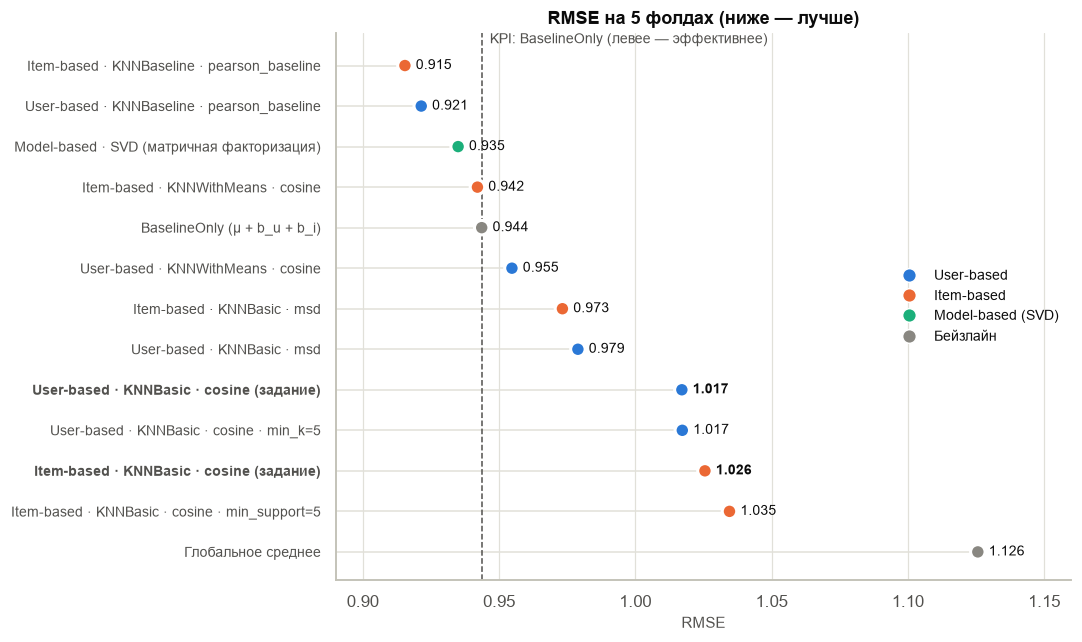

Случайный NormalPredictor не показан на графике: RMSE = 1.521


In [34]:
plot_df = leaderboard[leaderboard['Модель'] != 'NormalPredictor (случайный)'].iloc[::-1]
colors = plot_df['Подход'].map({'User-based': C_USER, 'Item-based': C_ITEM,
                                'Model-based': C_SVD, 'Бейзлайн': C_BASE})
labels = plot_df['Подход'].where(plot_df['Подход'] == 'Бейзлайн', plot_df['Подход'] + ' · ') \
    .str.replace('Бейзлайн', '') + plot_df['Модель']

# Точечная диаграмма: ось RMSE начинается не с нуля, поэтому точки, а не столбцы
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(plot_df))
ax.hlines(y, 0.89, plot_df['RMSE'], color=GRID, lw=1, zorder=1)
ax.scatter(plot_df['RMSE'], y, s=90, c=colors, edgecolors='white', linewidths=2, zorder=3)
for yy, (v, name) in enumerate(zip(plot_df['RMSE'], plot_df['Модель'])):
    ax.text(v + 0.004, yy, f'{v:.3f}', va='center', fontsize=9,
            color=INK, fontweight='bold' if 'задание' in name else 'normal')
ax.set_yticks(y, labels, fontsize=9)
for lbl, name in zip(ax.get_yticklabels(), plot_df['Модель']):
    if 'задание' in name:
        lbl.set_fontweight('bold')
ax.axvline(base['test_rmse'].mean(), color=INK_2, ls='--', lw=1, zorder=2)
ax.text(base['test_rmse'].mean() + 0.003, len(plot_df) - 0.45, 'KPI: BaselineOnly (левее — эффективнее)',
        color=INK_2, fontsize=9, ha='left')
ax.set_xlim(0.89, 1.16)
ax.set_ylim(-0.7, len(plot_df) - 0.2)
ax.set(title='RMSE на 5 фолдах (ниже — лучше)', xlabel='RMSE')
ax.grid(axis='y', visible=False)
handles = [matplotlib.lines.Line2D([], [], marker='o', ls='', ms=9, mfc=c, mec='white', label=l) for l, c in
           [('User-based', C_USER), ('Item-based', C_ITEM), ('Model-based (SVD)', C_SVD), ('Бейзлайн', C_BASE)]]
ax.legend(handles=handles, loc='center right')
plt.tight_layout()
plt.show()

print('Случайный NormalPredictor не показан на графике: RMSE = '
      f"{cv_results[('NormalPredictor (случайный)', 'Бейзлайн')]['test_rmse'].mean():.3f}")

**Классификация по KPI:**
* **Обе модели из задания неэффективны.** Они на 9–10 % точнее глобального среднего (RMSE 1,126), но уступают простой модели смещений `BaselineOnly` (RMSE 0,944) на всех 5 фолдах. В такой конфигурации соседи дают **меньше** информации, чем две поправки — «строгость» пользователя и общее восприятие фильма. Причина установлена на этапах 2–3: без нормализации косинус на «сырых» оценках почти не различает соседей.
* **Защита от малой поддержки точность не повышает:** `min_k = 5` у User-based не меняет RMSE, а `min_support = 5` у Item-based даже ухудшает его (1,035 против 1,026) — модель теряет часть соседей. Значит, точность моделей из задания ограничена прежде всего отсутствием нормализации. Зато эти настройки сильно меняют качество top-10 — см. этап 5.
* **Более «зоркая» мера сходства** (`msd`) улучшает RMSE на 0,04–0,05, и Item-based уже обгоняет User-based, но до уровня `BaselineOnly` обе модели не дотягивают.
* **Нормализация меняет картину.** С центрированием (`KNNWithMeans`) Item-based выходит на уровень `BaselineOnly` — пограничный класс: лучше на 4 из 5 фолдов. С учётом смещений и корреляцией с усадкой (`KNNBaseline + pearson_baseline`) оба подхода становятся **эффективными**, а лучшим оказывается **Item-based** (RMSE 0,9155, MAE 0,7182) — точнее даже `SVD` с параметрами по умолчанию (0,9350).
* **Вывод «какой подход точнее» зависит от конфигурации.** Преимущество User-based существует только при косинусе на «сырых» оценках. Как только мера сходства начинает различать соседей или оценки нормализуются, точнее становится Item-based: сходства фильмов шумнее из-за малой поддержки, но когда шум подавлен усадкой, они информативнее сходств пользователей.

### 4.4. Чувствительность к числу соседей k
Проверим, не является ли вывод о User-based и Item-based артефактом выбранного `k = 40`.

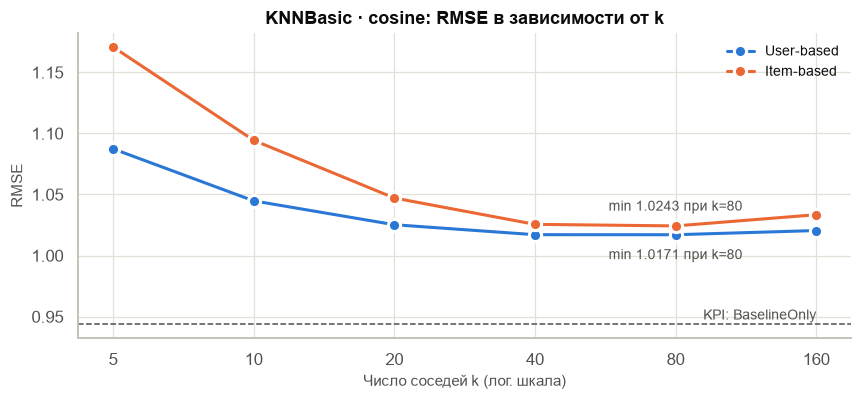

,User-based,Item-based
k,,
5,1.0874,1.1708
10,1.0448,1.0943
20,1.0252,1.0471
40,1.0171,1.0255
80,1.0171,1.0243
160,1.0205,1.0334


In [35]:
k_grid = [5, 10, 20, 40, 80, 160]
k_curve = {name: [] for name in ['User-based', 'Item-based']}
for k in k_grid:
    for name, sim_options in [('User-based', sim_options_user), ('Item-based', sim_options_item)]:
        res = cross_validate(KNNBasic(k=k, sim_options=sim_options, verbose=False), data, measures=['RMSE'], cv=kf)
        k_curve[name].append(res['test_rmse'].mean())
k_curve = pd.DataFrame(k_curve, index=pd.Index(k_grid, name='k'))

fig, ax = plt.subplots(figsize=(8, 3.8))
for name, color in [('User-based', C_USER), ('Item-based', C_ITEM)]:
    ax.plot(k_grid, k_curve[name], marker='o', ms=8, mec='white', mew=2, lw=2, color=color, label=name)
    best_k = k_curve[name].idxmin()
    ax.annotate(f'min {k_curve[name].min():.4f} при k={best_k}', (best_k, k_curve[name].min()),
                xytext=(0, -16 if name == 'User-based' else 10), textcoords='offset points',
                ha='center', fontsize=9, color=INK_2)
ax.axhline(base['test_rmse'].mean(), color=INK_2, ls='--', lw=1)
ax.text(k_grid[-1], base['test_rmse'].mean() + 0.004, 'KPI: BaselineOnly', ha='right', color=INK_2, fontsize=9)
ax.set_xscale('log')
ax.set_xticks(k_grid, [str(k) for k in k_grid])
ax.set(title='KNNBasic · cosine: RMSE в зависимости от k', xlabel='Число соседей k (лог. шкала)', ylabel='RMSE')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()
k_curve.round(4)

User-based точнее Item-based **при любом** k из сетки, так что вывод базового сравнения не зависит от выбора k. Оптимум для обеих моделей — 40–80 соседей (значение по умолчанию `k = 40` удачное); при малых k прогнозы шумные, при больших в соседи попадают малопохожие объекты. Ни при каком k модели не достигают уровня `BaselineOnly`: подбор k не заменяет нормализацию.

## Этап 5. Проверка «в полях» и выводы
### 5.1. Случайный пользователь и его вкусы

In [36]:
rng = np.random.default_rng(SEED)
user_ids = np.sort(ratings['user_id'].unique())
random_user = int(rng.choice(user_ids))

history = ratings[ratings['user_id'] == random_user].merge(movies, on='item_id').merge(
    item_stats, left_on='item_id', right_index=True)
print(f'Пользователь {random_user}: {len(history)} оценок — больше, чем у '
      f'{(user_stats["n_ratings"] < len(history)).mean():.0%} пользователей; '
      f'средняя {history["rating"].mean():.2f} (по всем пользователям {ratings["rating"].mean():.2f}); '
      f'доля оценок 4–5: {(history["rating"] >= 4).mean():.0%}')

# Жанровый профиль: доля фильмов жанра в истории пользователя против доли в каталоге
user_genres = history[GENRES].mean()
catalog_genres = ratings.merge(movies, on='item_id')[GENRES].mean()
genre_profile = pd.DataFrame({
    'Доля в оценках пользователя': user_genres,
    'Доля в оценках всех пользователей': catalog_genres,
    'Средняя оценка пользователя в жанре': [history.loc[history[g] == 1, 'rating'].mean() for g in GENRES],
})
genre_profile['Отношение долей'] = genre_profile['Доля в оценках пользователя'] / genre_profile['Доля в оценках всех пользователей']
display(genre_profile[genre_profile['Доля в оценках пользователя'] >= 0.05]
        .sort_values('Доля в оценках пользователя', ascending=False).round(2))

print('Фильмы, которые пользователь оценил выше всего:')
history[['title', 'genres', 'rating', 'n_ratings']].rename(
    columns={'title': 'Фильм', 'genres': 'Жанры', 'rating': 'Оценка', 'n_ratings': 'Оценок у фильма'}
).sort_values(['Оценка', 'Оценок у фильма'], ascending=False).head(12).reset_index(drop=True)

Пользователь 85: 288 оценок — больше, чем у 94% пользователей; средняя 3.54 (по всем пользователям 3.53); доля оценок 4–5: 54%


,Доля в оценках пользователя,Доля в оценках всех пользователей,Средняя оценка пользователя в жанре,Отношение долей
Drama,0.53,0.40,3.55,1.32
Comedy,0.30,0.30,3.54,1.01
Romance,0.18,0.19,3.77,0.93
Action,0.16,0.26,3.41,0.62
War,0.11,0.09,3.76,1.22
Adventure,0.11,0.14,3.25,0.81
Thriller,0.10,0.22,3.31,0.46
Sci-Fi,0.09,0.13,3.65,0.71
Musical,0.08,0.05,3.79,1.68
Children's,0.08,0.07,3.52,1.11


Фильмы, которые пользователь оценил выше всего:


,Фильм,Жанры,Оценка,Оценок у фильма
0,Star Wars (1977),"Action, Adventure, Romance, Sci-Fi, War",5.0,583
1,"Godfather, The (1972)","Action, Crime, Drama",5.0,413
2,"Shawshank Redemption, The (1994)",Drama,5.0,283
3,2001: A Space Odyssey (1968),"Drama, Mystery, Sci-Fi, Thriller",5.0,259
4,"Wizard of Oz, The (1939)","Adventure, Children's, Drama, Musical",5.0,246
5,Casablanca (1942),"Drama, Romance, War",5.0,243
6,"Graduate, The (1967)","Drama, Romance",5.0,239
7,"Godfather: Part II, The (1974)","Action, Crime, Drama",5.0,209
8,M*A*S*H (1970),"Comedy, War",5.0,206
9,"Boot, Das (1981)","Action, Drama, War",5.0,201


**Портрет пользователя 85.** Активный зритель: 288 оценок — больше, чем у 94 % пользователей; средняя оценка (3,54) совпадает с общей, то есть шкалу он использует «как все». Драм в его истории в 1,3 раза больше, чем в среднем по сервису (53 % оценок), заметен интерес к военному кино и мюзиклам; боевики и особенно триллеры он смотрит реже среднего. Высшие оценки — классика: «Godfather» I и II, «Casablanca», «Citizen Kane», «2001: A Space Odyssey», «Wizard of Oz», «The Graduate», «Das Boot», а также комедии «M\*A\*S\*H» и «Young Frankenstein». Хорошая рекомендация для него — признанная классика и авторское кино, прежде всего драмы.

### 5.2. Что рекомендуют модели из задания
Для пользователя прогнозируются оценки всех фильмов, которые он ещё не оценил, и берутся 10 с наибольшим прогнозом (при равенстве — более популярный). Чтобы оценить надёжность, рядом с прогнозом выведены число соседей, по которым он построен (`actual_k`), и число оценок у фильма во всём датасете.

In [37]:
all_raw_items = [full_trainset.to_raw_iid(i) for i in full_trainset.all_items()]
RARE = 5   # «редкий» фильм — меньше 5 оценок во всём датасете


def recommend(algo, raw_uid, n=10):
    """Top-n фильмов, которые пользователь ещё не оценивал, по убыванию прогноза."""
    inner_uid = full_trainset.to_inner_uid(str(raw_uid))
    seen = {full_trainset.to_raw_iid(j) for j, _ in full_trainset.ur[inner_uid]}
    preds = algo.test([(str(raw_uid), iid, 0) for iid in all_raw_items if iid not in seen])
    recs = pd.DataFrame({'item_id': [int(p.iid) for p in preds], 'Прогноз': [p.est for p in preds],
                         'Соседей (actual_k)': [p.details.get('actual_k', np.nan) for p in preds]})
    recs = recs.merge(item_stats, left_on='item_id', right_index=True)
    recs = recs.sort_values(['Прогноз', 'n_ratings'], ascending=[False, False]).head(n)
    recs = recs.merge(movies[['item_id', 'title', 'genres']], on='item_id')
    return recs.rename(columns={'title': 'Фильм', 'genres': 'Жанры', 'n_ratings': 'Оценок у фильма',
                                'mean_rating': 'Средняя у фильма'})[
        ['item_id', 'Фильм', 'Жанры', 'Прогноз', 'Соседей (actual_k)', 'Оценок у фильма', 'Средняя у фильма']]


rec_cols = ['Фильм', 'Жанры', 'Прогноз', 'Соседей (actual_k)', 'Оценок у фильма', 'Средняя у фильма']
recs_user = recommend(full_user, random_user)
recs_item = recommend(full_item, random_user)

print(f'User-based (KNNBasic · cosine) — рекомендации для пользователя {random_user}:')
display(recs_user[rec_cols].round(2))
print(f'Item-based (KNNBasic · cosine) — рекомендации для пользователя {random_user}:')
display(recs_item[rec_cols].round(2))


def describe_recs(recs):
    stats = {'Медиана оценок у фильма': recs['Оценок у фильма'].median(),
             f'Редких фильмов (< {RARE} оценок)': (recs['Оценок у фильма'] < RARE).sum(),
             'Фильмов с 1 оценкой': (recs['Оценок у фильма'] == 1).sum(),
             'Медиана actual_k': recs['Соседей (actual_k)'].median(),
             'Средняя оценка фильмов в списке': round(recs['Средняя у фильма'].mean(), 2)}
    return {k: f'{v:g}' for k, v in stats.items()}


display(pd.DataFrame({'User-based': describe_recs(recs_user), 'Item-based': describe_recs(recs_item)}))
print('Общих фильмов в двух списках:', len(set(recs_user['item_id']) & set(recs_item['item_id'])))

User-based (KNNBasic · cosine) — рекомендации для пользователя 85:


,Фильм,Жанры,Прогноз,Соседей (actual_k),Оценок у фильма,Средняя у фильма
0,Star Kid (1997),"Adventure, Children's, Fantasy, Sci-Fi",5.0,3,3,5.0
1,Santa with Muscles (1996),Comedy,5.0,2,2,5.0
2,"Saint of Fort Washington, The (1993)",Drama,5.0,2,2,5.0
3,"Great Day in Harlem, A (1994)",Documentary,5.0,1,1,5.0
4,Someone Else's America (1995),Drama,5.0,1,1,5.0
5,Entertaining Angels: The Dorothy Day Story (1996),Drama,5.0,1,1,5.0
6,They Made Me a Criminal (1939),"Crime, Drama",5.0,1,1,5.0
7,Marlene Dietrich: Shadow and Light (1996),Documentary,5.0,1,1,5.0
8,Prefontaine (1997),Drama,5.0,3,3,5.0
9,Aiqing wansui (1994),Drama,5.0,1,1,5.0


Item-based (KNNBasic · cosine) — рекомендации для пользователя 85:


,Фильм,Жанры,Прогноз,Соседей (actual_k),Оценок у фильма,Средняя у фильма
0,Rear Window (1954),"Mystery, Thriller",3.95,40,209,4.39
1,12 Angry Men (1957),Drama,3.95,40,125,4.34
2,L.A. Confidential (1997),"Crime, Film-Noir, Mystery, Thriller",3.90,40,297,4.16
3,Nobody Loves Me (Keiner liebt mich) (1994),"Comedy, Drama",3.85,40,1,1.00
4,Heavenly Creatures (1994),"Drama, Fantasy, Thriller",3.85,40,70,3.67
5,"Professional, The (1994)","Crime, Drama, Romance, Thriller",3.85,40,149,3.70
6,Losing Chase (1996),Drama,3.82,40,8,3.25
7,"Maltese Falcon, The (1941)","Film-Noir, Mystery",3.82,40,138,4.21
8,"Wrong Trousers, The (1993)","Animation, Comedy",3.82,40,118,4.47
9,Looking for Richard (1996),"Documentary, Drama",3.82,40,55,3.73


,User-based,Item-based
Медиана оценок у фильма,1,121.5
Редких фильмов (< 5 оценок),10,1
Фильмов с 1 оценкой,6,1
Медиана actual_k,1,40
Средняя оценка фильмов в списке,5,3.69


Общих фильмов в двух списках: 0


**Интерпретация рекомендаций для пользователя 85.**

**User-based** рекомендует 10 почти никому не известных фильмов с 1–3 оценками («Star Kid», «Santa with Muscles», документальные «A Great Day in Harlem» и «Marlene Dietrich: Shadow and Light» и др.). Каждый прогноз равен 5,0 и построен по 1–3 соседям (`actual_k`). Механизм: если все зрители фильма (от одного до трёх человек) поставили «5» и оказались среди соседей, а при косинусе ≈ 0,95 соседом оказывается почти любой, то прогноз просто равен их оценке. Список не связан со вкусом пользователя и доверия не заслуживает. Хороший RMSE модель набирает на популярных фильмах, а в top-N попадают как раз фильмы с минимальной поддержкой.

**Item-based** даёт осмысленный список: «Rear Window», «12 Angry Men», «L.A. Confidential», «Maltese Falcon», «Wrong Trousers» — признанные фильмы со средней оценкой 4,2–4,5, в основном классика, нуар и драма. Это хорошо совпадает с профилем пользователя, и каждый прогноз опирается на 40 соседей. Но и здесь есть сбой: «Nobody Loves Me» с единственной оценкой «1» получил прогноз 3,85. У фильма с одним зрителем сходство с любым фильмом этого зрителя равно 1, и прогноз превращается в среднюю оценку пользователя по фильмам, которые случайно совпали с фильмами того единственного зрителя. Кроме того, прогнозы сжаты в узкий диапазон 3,82–3,95: порядок в списке решают сотые доли, и он неустойчив.

Списки двух моделей не пересекаются ни одним фильмом.

### 5.3. Масштаб проблемы: проверка на 200 случайных пользователях
Один пользователь — частный случай, поэтому те же показатели надёжности посчитаны для top-10 у 200 других случайных пользователей. Дополнительно оценивается разнообразие — **покрытие каталога**: сколько разных фильмов попало во все 2 000 рекомендаций. Для сравнения добавлены варианты с защитой от малой поддержки и лучшая по KPI модель из п. 4.3.

In [38]:
eval_users = rng.choice(np.setdiff1d(user_ids, [random_user]), size=200, replace=False)

field_models = {
    ('KNNBasic · cosine (задание)', 'User-based'): full_user,
    ('KNNBasic · cosine (задание)', 'Item-based'): full_item,
    ('KNNBasic · cosine · min_k=5', 'User-based'): knn(KNNBasic, 'User-based', min_k=5).fit(full_trainset),
    ('KNNBasic · cosine · min_support=5', 'Item-based'): knn(KNNBasic, 'Item-based', min_support=5).fit(full_trainset),
    ('KNNBaseline · pearson_baseline', 'Item-based'): knn(KNNBaseline, 'Item-based', 'pearson_baseline').fit(full_trainset),
}

field_rows = []
top_lists = {}
for key, algo in field_models.items():
    lists = [recommend(algo, u) for u in eval_users]
    flat = pd.concat(lists)
    top_lists[key] = flat
    field_rows.append({
        'Подход': key[1], 'Модель': key[0],
        'RMSE (CV)': cv_results[key]['test_rmse'].mean(),
        f'Доля редких (< {RARE} оценок) в top-10': (flat['Оценок у фильма'] < RARE).mean(),
        'Доля фильмов с 1 оценкой': (flat['Оценок у фильма'] == 1).mean(),
        'Медиана оценок у фильма': flat['Оценок у фильма'].median(),
        'Разных фильмов во всех списках': flat['item_id'].nunique(),
        'Покрытие каталога': flat['item_id'].nunique() / n_items,
    })
field = pd.DataFrame(field_rows)
field.style.format({'RMSE (CV)': '{:.4f}', f'Доля редких (< {RARE} оценок) в top-10': '{:.1%}',
                    'Доля фильмов с 1 оценкой': '{:.1%}', 'Медиана оценок у фильма': '{:.0f}',
                    'Покрытие каталога': '{:.1%}'})

,Подход,Модель,RMSE (CV),Доля редких (< 5 оценок) в top-10,Доля фильмов с 1 оценкой,Медиана оценок у фильма,Разных фильмов во всех списках,Покрытие каталога
0,User-based,KNNBasic · cosine (задание),1.0171,99.5%,58.1%,1,22,1.3%
1,Item-based,KNNBasic · cosine (задание),1.0255,71.9%,56.0%,1,483,28.7%
2,User-based,KNNBasic · cosine · min_k=5,1.0172,0.0%,0.0%,173,82,4.9%
3,Item-based,KNNBasic · cosine · min_support=5,1.0346,0.0%,0.0%,6,271,16.1%
4,Item-based,KNNBaseline · pearson_baseline,0.9155,21.1%,0.0%,121,338,20.1%


**Проблема системная, а пользователь 85 — скорее исключение:**
* **User-based из задания:** 99,5 % рекомендованных фильмов — редкие, а все 2 000 рекомендаций приходятся всего на 22 фильма (1,3 % каталога). Всем предлагаются одни и те же фильмы с единственной «пятёркой» — персонализации нет.
* **Item-based из задания:** 72 % рекомендаций — редкие фильмы, 56 % — с единственной оценкой. У пользователя 85 это почти не проявилось, потому что он очень активен. «Соседями» фильма с одним зрителем становятся все фильмы этого зрителя, которые оценил пользователь; при 288 оценках таких фильмов много, и прогноз сглаживается к средней пользователя. У менее активного пользователя пересечение маленькое, и прогноз становится крайним — 5,0 при одной совпавшей «пятёрке».
* **User-based с `min_k = 5`** полностью убирает редкие фильмы при том же RMSE, но смещает рекомендации к хитам: медиана — 173 оценки у фильма, на 200 пользователей — всего 82 разных фильма (4,9 % каталога). Надёжно, но персонализация слабая.
* **Item-based с `min_support = 5`** тоже убирает редкие фильмы, но списки остаются нишевыми (медиана — 6 оценок у фильма), а RMSE хуже.
* **Item-based `KNNBaseline`** (лучшая по KPI) даёт лучший баланс: фильмов с одной оценкой нет, медиана популярности — 121 оценка, покрытие — 20 % каталога. Однако 21 % рекомендаций всё ещё приходится на фильмы с 2–4 оценками — им тоже нужен порог надёжности.

Главный урок «полевой» проверки: **RMSE измеряет точность на оценках, которые пользователи уже поставили, и почти не замечает, что модель делает с редкими фильмами.** Поэтому RMSE и MAE нужно дополнять проверкой самих списков рекомендаций.

### 5.4. Рекомендации лучшей по KPI модели для того же пользователя

In [39]:
best_key = ('KNNBaseline · pearson_baseline', 'Item-based')
recs_best = recommend(field_models[best_key], random_user)
print(f'{best_key[1]} · {best_key[0]} — рекомендации для пользователя {random_user}:')
display(recs_best[rec_cols].round(2))
display(pd.DataFrame({'Item-based KNNBaseline': describe_recs(recs_best)}))
print('Общих фильмов со списком Item-based KNNBasic:', len(set(recs_best['item_id']) & set(recs_item['item_id'])))

Item-based · KNNBaseline · pearson_baseline — рекомендации для пользователя 85:


,Фильм,Жанры,Прогноз,Соседей (actual_k),Оценок у фильма,Средняя у фильма
0,"Close Shave, A (1995)","Animation, Comedy, Thriller",4.50,40,112,4.49
1,"Wrong Trousers, The (1993)","Animation, Comedy",4.31,40,118,4.47
2,12 Angry Men (1957),Drama,4.31,40,125,4.34
3,Rear Window (1954),"Mystery, Thriller",4.27,40,209,4.39
4,Secrets & Lies (1996),Drama,4.22,40,162,4.27
5,Wallace & Gromit: The Best of Aardman Animation (1996),Animation,4.20,40,67,4.45
6,"Maltese Falcon, The (1941)","Film-Noir, Mystery",4.20,40,138,4.21
7,Salut cousin! (1996),"Comedy, Drama",4.15,1,2,2.00
8,"To Have, or Not (1995)",Drama,4.15,1,2,2.00
9,L.A. Confidential (1997),"Crime, Film-Noir, Mystery, Thriller",4.14,40,297,4.16


,Item-based KNNBaseline
Медиана оценок у фильма,121.5
Редких фильмов (< 5 оценок),2
Фильмов с 1 оценкой,0
Медиана actual_k,40
Средняя оценка фильмов в списке,3.88


Общих фильмов со списком Item-based KNNBasic: 5


Лучшая по KPI модель предлагает пользователю 85 признанные фильмы с высокой средней оценкой: «A Close Shave» и «The Wrong Trousers», «12 Angry Men», «Rear Window», «Secrets & Lies», «The Maltese Falcon», «L.A. Confidential». Половина списка совпадает с Item-based из задания, но прогнозы стали увереннее (4,1–4,5 вместо 3,8–3,95) и лучше различают фильмы. Список отражает интерес пользователя к классике, детективу и драме, а британская комедия соответствует его высоким оценкам комедий («M\*A\*S\*H», «Young Frankenstein»). Заметна и особенность модели: учёт смещения фильма $b_i$ поднимает вверх фильмы, которые высоко оценивают все.

Слабое место прежнее: «Salut cousin!» и «To Have, or Not» — фильмы с двумя оценками и средней 2,0 — получили прогноз 4,15 по **одному** соседу (`actual_k = 1`). `KNNBaseline` целиком переносит отклонение пользователя на единственном соседе, поэтому прогноз может оказаться высоким даже для слабо оценённого фильма. В рабочей системе этой модели нужен `min_k ≥ 5` или порог по числу оценок у фильма.

## Итоговая таблица

In [40]:
main_keys = [('KNNBasic · cosine (задание)', 'User-based'), ('KNNBasic · cosine (задание)', 'Item-based')]
summary_rows = []
for key in main_keys + [best_key]:
    res = cv_results[key]
    fld = field.set_index(['Модель', 'Подход']).loc[key]
    summary_rows.append({
        'Подход': key[1], 'Модель': key[0],
        'RMSE (5 фолдов)': f"{res['test_rmse'].mean():.4f} ± {res['test_rmse'].std():.4f}",
        'MAE (5 фолдов)': f"{res['test_mae'].mean():.4f} ± {res['test_mae'].std():.4f}",
        'Обучение, с': round(np.mean(res['fit_time']), 2),
        'KPI': kpi_class(res),
        f'Редких фильмов в top-10 (200 польз.)': f"{fld[f'Доля редких (< {RARE} оценок) в top-10']:.1%}",
        'Покрытие каталога': f"{fld['Покрытие каталога']:.1%}",
    })
for name in ['BaselineOnly (μ + b_u + b_i)', 'Глобальное среднее']:
    res = cv_results[(name, 'Бейзлайн')]
    summary_rows.append({'Подход': 'Бейзлайн', 'Модель': name,
                         'RMSE (5 фолдов)': f"{res['test_rmse'].mean():.4f} ± {res['test_rmse'].std():.4f}",
                         'MAE (5 фолдов)': f"{res['test_mae'].mean():.4f} ± {res['test_mae'].std():.4f}",
                         'Обучение, с': round(np.mean(res['fit_time']), 2), 'KPI': 'ориентир',
                         f'Редких фильмов в top-10 (200 польз.)': '—', 'Покрытие каталога': '—'})
pd.DataFrame(summary_rows)

,Подход,Модель,RMSE (5 фолдов),MAE (5 фолдов),"Обучение, с",KPI,Редких фильмов в top-10 (200 польз.),Покрытие каталога
0,User-based,KNNBasic · cosine (задание),1.0171 ± 0.0047,0.8044 ± 0.0048,1.34,Неэффективна,99.5%,1.3%
1,Item-based,KNNBasic · cosine (задание),1.0255 ± 0.0033,0.8110 ± 0.0037,1.71,Неэффективна,71.9%,28.7%
2,Item-based,KNNBaseline · pearson_baseline,0.9155 ± 0.0038,0.7182 ± 0.0033,1.79,Эффективна,21.1%,20.1%
3,Бейзлайн,BaselineOnly (μ + b_u + b_i),0.9436 ± 0.0037,0.7481 ± 0.0036,0.18,ориентир,—,—
4,Бейзлайн,Глобальное среднее,1.1257 ± 0.0054,0.9447 ± 0.0050,0.02,ориентир,—,—


## Выводы
1. **Данные.** MovieLens 100K разрежен на **93,7 %**: на пользователя в среднем 106 оценок, на фильм — 59,5, у фильмов «длинный хвост» (141 фильм с одной оценкой). Оценки смещены вверх (средняя 3,53), пользователи по-разному используют шкалу. Для KNN критична поддержка сходства: у пар пользователей медиана — 10 общих фильмов, у пар фильмов — всего 1 общий зритель.
2. **Ответ на вопрос задания.** В конфигурации задания (`KNNBasic`, косинус, k = 40, кросс-валидация на 5 фолдах) **точнее User-based**: RMSE 1,0171 ± 0,0047 и MAE 0,8044 против 1,0255 ± 0,0033 и 0,8110 у Item-based. Превосходство устойчиво — на всех 5 фолдах по обеим метрикам и при любом k от 5 до 160. Причина — более плотная поддержка сходства пользователей.
3. **По KPI обе модели из задания неэффективны:** они уступают простой модели смещений `BaselineOnly` (RMSE 0,9436) на всех фолдах. Косинус на ненормированных положительных оценках почти не различает соседей (среднее сходство ≈ 0,95), а при одной общей оценке даёт сходство 1.
4. **С нормализацией вывод меняется.** Item-based точнее User-based уже при мере `msd` и при центрировании (`KNNWithMeans`). `KNNBaseline` с `pearson_baseline` делает оба подхода эффективными, и лучшим становится **Item-based: RMSE 0,9155, MAE 0,7182** — на 10–11 % ниже, чем у моделей задания, и лучше `SVD` с параметрами по умолчанию.
5. **«Полевая» проверка показала то, чего не видно в RMSE.** User-based из задания при лучшем RMSE рекомендует всем одни и те же фильмы с единственной «пятёркой» (99,5 % редких фильмов, 22 фильма на 200 пользователей). Item-based из задания дал пользователю 85 осмысленный список классики, но на выборке пользователей тоже заполнен редкими фильмами (72 %). Качество рекомендательной системы нужно оценивать и по спискам: доле ненадёжных рекомендаций, покрытию каталога, ранжирующим метрикам.
6. **Рекомендация.** Для этой задачи выбрать **Item-based `KNNBaseline` + `pearson_baseline`** с порогом надёжности (`min_k ≥ 5` или минимальное число оценок у фильма); User-based использовать только с `min_k ≥ 5`. Следующие шаги — подбор `k`, `shrinkage` и `min_k` через `GridSearchCV`, ранжирующие метрики (Precision@K, Recall@K, NDCG) и сравнение с `SVD++`.